# From Public Observations to a Checked Portfolio Decision

The variance of a portfolio is a quadratic form:

$$
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad \mathbf 1^{\mathsf T}w=1,
\qquad w_i\geq0.
$$

Here, $w$ is the vector of portfolio weights, $\Sigma$ is the return covariance matrix, $\sigma_p^2$ is portfolio variance, $\mathbf 1$ is a vector of ones, and $w_i\geq0$ requires a long-only allocation.

Row,Field,Value
,String,Any
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Return type,Daily value-weighted return
4,Study start,2019-01-02
5,Study end,2025-12-31
6,Complete observations,1760
7,Selected industries,16
8,Selection rule,First sixteen industries in archive order


Row,Period,Start date,End date,Observations,Use
,String,Date,Date,Int64,String
1,Training,2019-01-02,2021-12-31,757,Estimate candidates
2,Validation,2022-01-03,2023-12-29,501,Choose one method
3,Final test,2024-01-02,2025-12-31,502,Evaluate frozen method


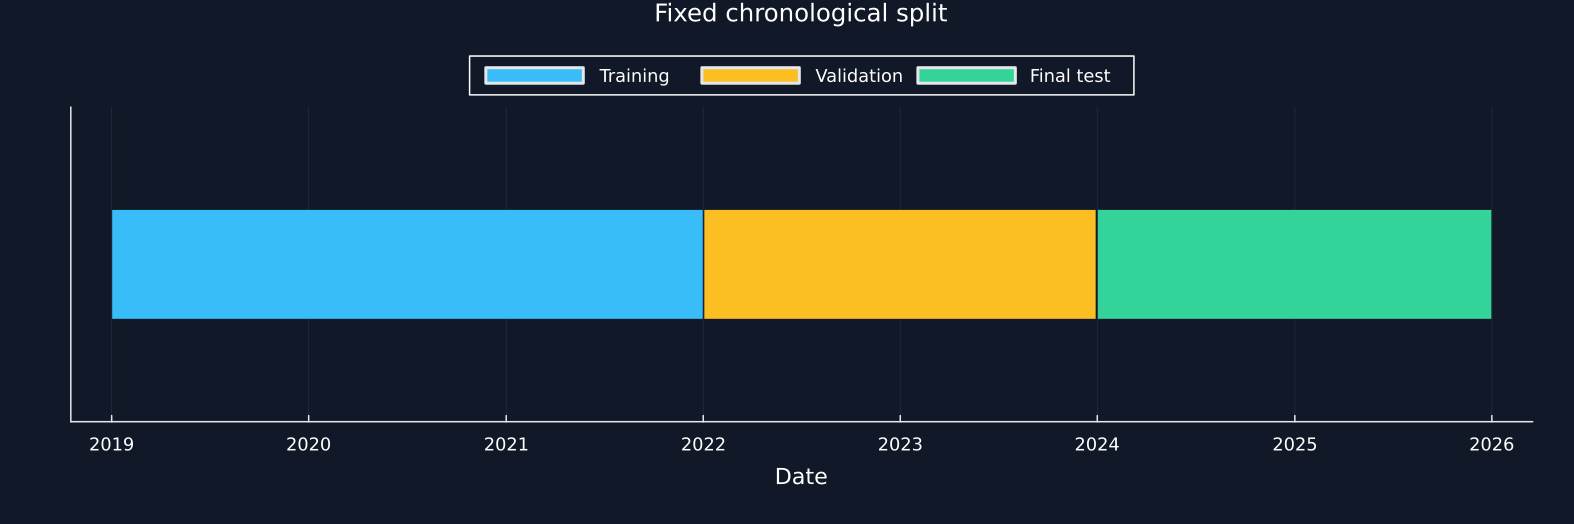

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("32_reproducible_research_study");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
using RiskLabAI.ParallelWork
using RiskLabAI.Components
using RiskLabAI.Utils
muted = "#94A3B8"
asset_names = selected_assets
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter30-"*replace(name,"_"=>"-"))
    return nothing
end
function binance_rows(limit=5000)
    full = load_binance()
    return DataFrame("Date Time"=>full.time[1:limit],"Price"=>full.close[1:limit],"Volume"=>full.volume[1:limit])
end
date_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
function portfolio_weights(method,covariance,correlation)
    method=="Equal weight" && return fill(1/size(covariance,1),size(covariance,1))
    method=="Inverse variance" && return inverse_variance_weights(covariance)
    method=="Hierarchical risk parity" && return hrp(covariance,correlation)
    throw(KeyError(method))
end
function portfolio_record(method,weights,returns)
    daily = returns*weights
    wealth = cumprod(1 .+daily)
    drawdown = wealth./accumulate(max,wealth).-1
    concentration = sum(abs2,weights)
    return (Method=method,Observations=length(daily),annual_mean=mean(daily)*252,annual_volatility=std(daily)*sqrt(252),ratio=mean(daily)/std(daily)*sqrt(252),drawdown=minimum(drawdown),largest=maximum(weights),concentration=concentration,effective=1/concentration)
end
function portfolio_frame(records)
    frame = DataFrame(records)
    rename!(frame,["Method","Observations","Annual mean return","Annual volatility","Return to volatility","Maximum drawdown","Largest weight","Weight concentration","Effective holdings"])
    return sort(frame,["Annual volatility","Method"])
end
training_mask = dates.<=Date(2021,12,31)
validation_mask = (Date(2022,1,1).<=dates).&(dates.<=Date(2023,12,31))
final_mask = dates.>=Date(2024,1,1)
pretest_mask = dates.<=Date(2023,12,31)
training_returns,validation_returns,final_returns,pretest_returns = [public_sample[mask,:] for mask in [training_mask,validation_mask,final_mask,pretest_mask]]
split_masks = [training_mask,validation_mask,final_mask]
split_table = DataFrame("Period"=>["Training","Validation","Final test"],"Start date"=>[first(dates[mask]) for mask in split_masks],"End date"=>[last(dates[mask]) for mask in split_masks],"Observations"=>count.(split_masks),"Use"=>["Estimate candidates","Choose one method","Evaluate frozen method"])
data_provenance = DataFrame("Field"=>["Archive","Provider","Return type","Study start","Study end","Complete observations","Selected industries","Selection rule"],"Value"=>Any["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(dates)),string(last(dates)),length(dates),length(asset_names),"First sixteen industries in archive order"])
table(data_provenance,"final_study_provenance","Public data and fixed asset selection for the final study.")
table(split_table,"chronological_split","The fixed training, validation, and final test periods.")
epoch = Date(2019,1,1)
ticks = Date.(2019:2026,1,1)
figure = plot(;yticks=false,xlabel="Date",title="Fixed chronological split",xticks=(Dates.value.(ticks.-epoch),string.(year.(ticks))),ylims=(-.65,.65),legend=:outertop,legend_columns=3,size=(1050,350),bottom_margin=10Plots.mm)
for (row,color) in zip(eachrow(split_table),[palette.cyan,palette.amber,palette.green])
    left,right = Dates.value(row["Start date"]-epoch),Dates.value(row["End date"]-epoch)
    plot!(figure,Shape([left,right,right,left],[-.225,-.225,.225,.225]);color,linealpha=0,label=row.Period)
end
save_figure(figure,paths,"chronological_split")


## Three Fixed Candidate Methods

Equal weight and inverse variance use the following rules:

$$
w_i^{\mathrm{EW}}=\frac1p,
\qquad
w_i^{\mathrm{IV}}=\frac{1/\Sigma_{ii}}{\sum_{j=1}^{p}1/\Sigma_{jj}}.
$$

Here, $p$ is the number of industries, $w_i^{\mathrm{EW}}$ is the equal weight for industry $i$, $w_i^{\mathrm{IV}}$ is its inverse variance weight, and $\Sigma_{ii}$ is its estimated return variance. Hierarchical risk parity uses a correlation tree, covariance reordering, and recursive allocation instead of this closed form.

Row,Industry,Equal weight,Hierarchical risk parity,Inverse variance
,String,Float64,Float64,Float64
1,Agric,0.0625,0.0374867,0.0363075
2,Food,0.0625,0.110523,0.114307
3,Soda,0.0625,0.0751456,0.0777183
4,Beer,0.0625,0.0702283,0.0784381
5,Smoke,0.0625,0.0908453,0.0610825
6,Toys,0.0625,0.0352375,0.0267876
7,Fun,0.0625,0.0581387,0.0441972
8,Books,0.0625,0.0555344,0.0537875
9,Hshld,0.0625,0.0867102,0.0968468


Row,Method,Weight sum,Smallest weight,Largest weight,Weight concentration,Effective holdings,Training annual volatility
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Equal weight,1.0,0.0625,0.0625,0.0625,16.0,0.214478
2,Hierarchical risk parity,1.0,0.0300056,0.110523,0.0711564,14.0536,0.200792
3,Inverse variance,1.0,0.0201751,0.114307,0.0730301,13.693,0.199629


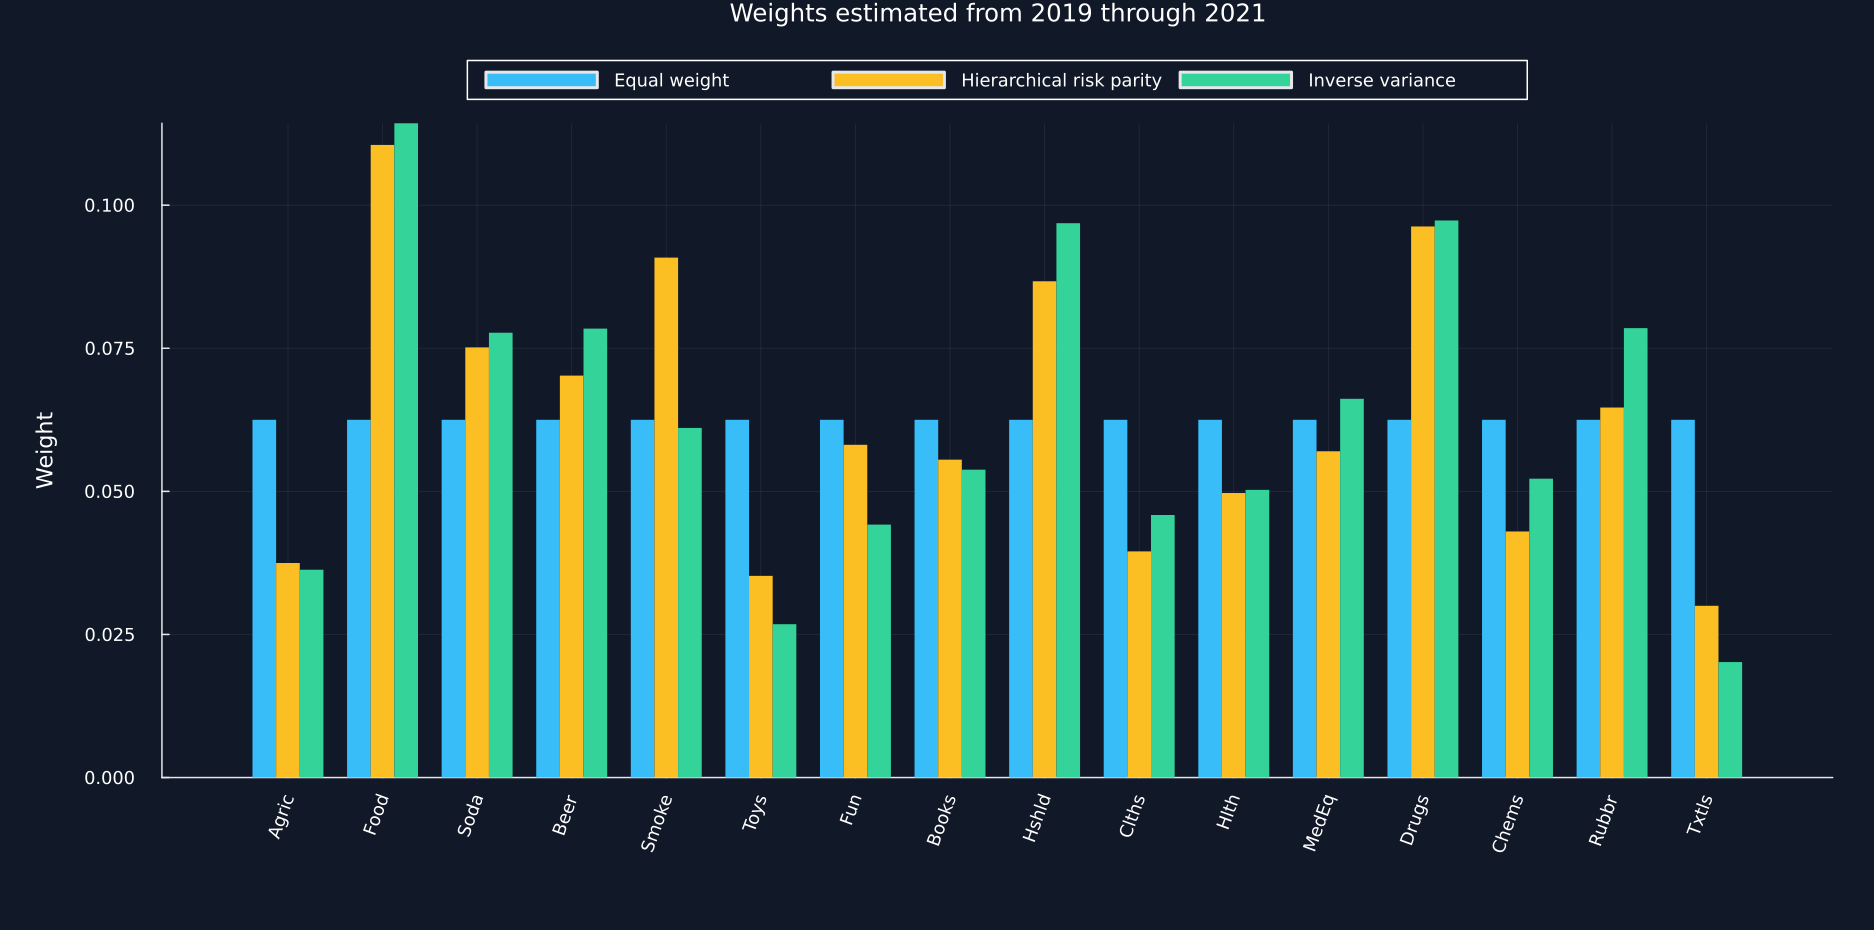

In [2]:
methods = ["Equal weight","Hierarchical risk parity","Inverse variance"]
method_colors = Dict(method=>color for (method,color) in zip(methods,[palette.cyan,palette.amber,palette.green]))
training_covariance,training_correlation = cov(training_returns)*252,cor(training_returns)
training_weights = Dict(method=>portfolio_weights(method,training_covariance,training_correlation) for method in methods)
training_weight_table = DataFrame("Industry"=>asset_names)
for method in methods
    training_weight_table[!,method] = training_weights[method]
end
training_diagnostics = DataFrame([(Method=method,net=sum(training_weights[method]),smallest=minimum(training_weights[method]),largest=maximum(training_weights[method]),concentration=sum(abs2,training_weights[method]),effective=1/sum(abs2,training_weights[method]),volatility=sqrt(dot(training_weights[method],training_covariance*training_weights[method]))) for method in methods])
rename!(training_diagnostics,["Method","Weight sum","Smallest weight","Largest weight","Weight concentration","Effective holdings","Training annual volatility"])
table(training_weight_table,"training_candidate_weights","Candidate portfolio weights estimated from the training period.")
table(training_diagnostics,"training_candidate_diagnostics","Weight and risk checks for the three training estimates.")
figure = plot(;xticks=(1:16,asset_names),xrotation=70,ylabel="Weight",title="Weights estimated from 2019 through 2021",legend=:outertop,legend_columns=3,size=(1250,620),bottom_margin=16Plots.mm)
for (index,method) in enumerate(methods)
    bar!(figure,(1:16).+(index-2)*.25,training_weights[method];bar_width=.25,color=method_colors[method],linealpha=0,label=method)
end
save_figure(figure,paths,"training_candidate_weights")
save_data(DataFrame(training_covariance,:auto),paths,"training_covariance")
save_data(DataFrame(training_correlation,:auto),paths,"training_correlation")
nothing


## Choosing on the Validation Period

The method is chosen by the smallest validation volatility, with alphabetical order used only for an exact tie:

$$
\widehat m=\arg\min_{m\in\mathcal M}^{\mathrm{alphabetical\ tie}}\sqrt{252}\,s\!\left(R_{\mathrm{val}}w_m^{\mathrm{train}}\right).
$$

Here, $\mathcal M$ is the fixed set of three methods, $w_m^{\mathrm{train}}$ is method $m$'s weight vector estimated from training data, $R_{\mathrm{val}}$ is the validation return matrix, $s(\cdot)$ is sample standard deviation, and $\widehat m$ is the selected method.

Row,Method,Observations,Annual mean return,Annual volatility,Return to volatility,Maximum drawdown,Largest weight,Weight concentration,Effective holdings
,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Inverse variance,501,-0.0166711,0.16547,-0.10075,-0.210646,0.114307,0.0730301,13.693
2,Hierarchical risk parity,501,-0.0170968,0.165962,-0.103016,-0.214513,0.110523,0.0711564,14.0536
3,Equal weight,501,-0.0346186,0.183369,-0.188792,-0.250805,0.0625,0.0625,16.0


Row,Decision item,Recorded value
,String,Any
1,Fixed candidates,3
2,Selection measure,Smallest validation annual volatility
3,Tie rule,Alphabetical method name
4,Selected method,Inverse variance
5,Final period used for choice,No


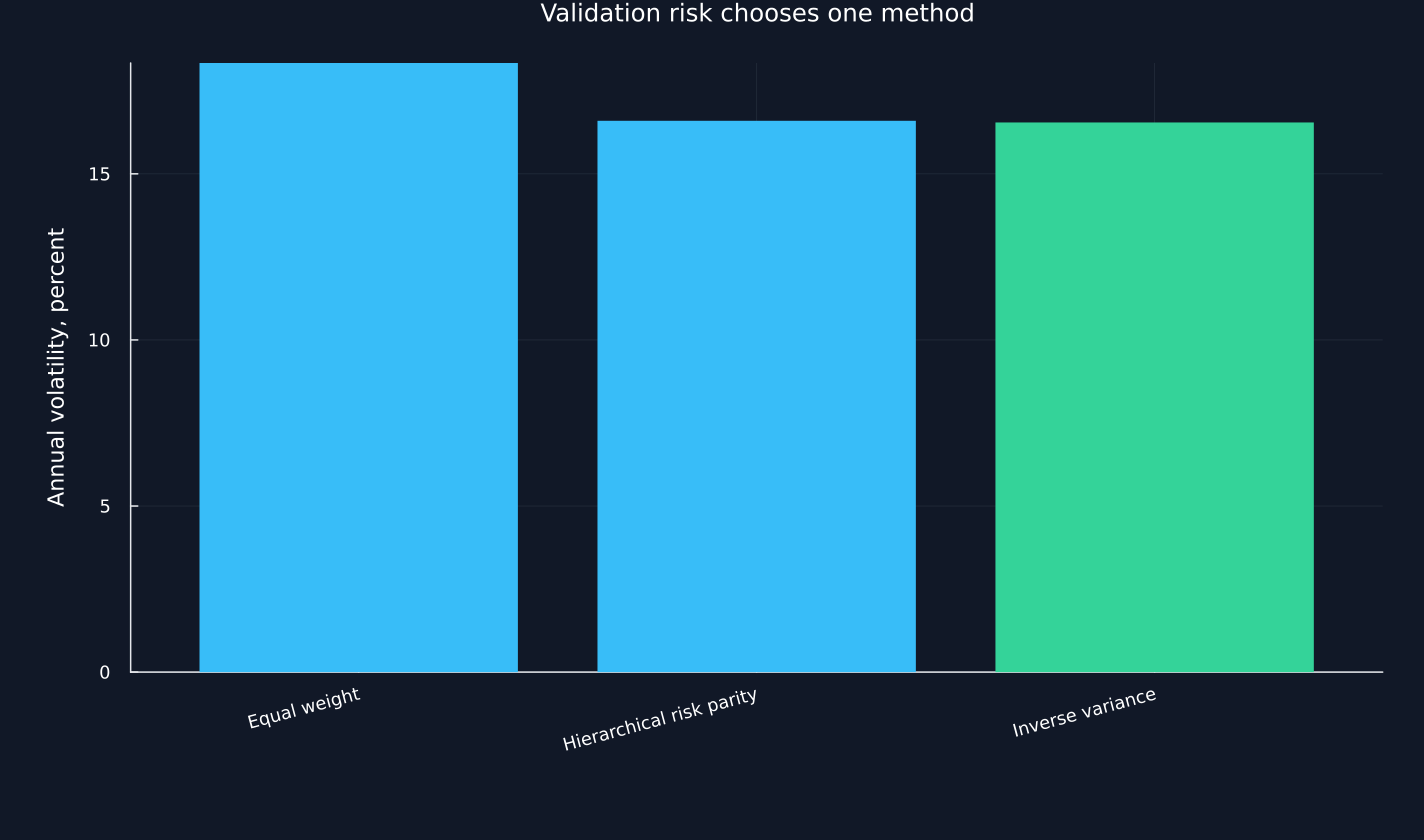

In [3]:
validation_table = portfolio_frame([portfolio_record(method,training_weights[method],validation_returns) for method in methods])
selected_method = first(validation_table.Method)
selection_table = DataFrame("Decision item"=>["Fixed candidates","Selection measure","Tie rule","Selected method","Final period used for choice"],"Recorded value"=>Any[length(methods),"Smallest validation annual volatility","Alphabetical method name",selected_method,"No"])
table(validation_table,"validation_method_comparison","Validation results for the three methods fixed before comparison.")
table(selection_table,"portfolio_selection_record","The fixed rule and its observed selection.")
ordered = sort(validation_table,:Method)
figure = bar(1:3,ordered[!,"Annual volatility"]*100;color=[method==selected_method ? palette.green : palette.cyan for method in ordered.Method],linealpha=0,legend=false,xticks=(1:3,ordered.Method),xrotation=15,ylabel="Annual volatility, percent",title="Validation risk chooses one method",bottom_margin=17Plots.mm,size=(950,560))
save_figure(figure,paths,"validation_risk")


## Refit Before the Final Test

Final period variance and weight concentration are measured as:

$$
\widehat\sigma_m^2=w_m^{\mathsf T}\widehat\Sigma_{\mathrm{test}}w_m,
\qquad H_m=\sum_{i=1}^{p}w_{m,i}^2,
\qquad N_{\mathrm{eff},m}=\frac1{H_m}.
$$

Here, $w_m$ is method $m$'s weight vector refitted with all observations through 2023, $\widehat\Sigma_{\mathrm{test}}$ is the final period covariance matrix, $H_m$ is weight concentration, and $N_{\mathrm{eff},m}$ is the effective number of equally weighted holdings.

Row,Industry,Equal weight,Hierarchical risk parity,Inverse variance
,String,Float64,Float64,Float64
1,Agric,0.0625,0.0425437,0.0396946
2,Food,0.0625,0.103594,0.119751
3,Soda,0.0625,0.10704,0.08507
4,Beer,0.0625,0.0934738,0.087214
5,Smoke,0.0625,0.0845767,0.0672172
6,Toys,0.0625,0.03072,0.0252399
7,Fun,0.0625,0.0407482,0.0334792
8,Books,0.0625,0.0553142,0.0516949
9,Hshld,0.0625,0.0833318,0.0963285


Row,Method,Observations,Annual mean return,Annual volatility,Return to volatility,Maximum drawdown,Largest weight,Weight concentration,Effective holdings
,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Hierarchical risk parity,502,0.0805724,0.120147,0.670616,-0.11703,0.109658,0.0754525,13.2534
2,Inverse variance,502,0.069786,0.121613,0.573836,-0.126689,0.119751,0.0749389,13.3442
3,Equal weight,502,0.0822828,0.134535,0.611606,-0.149905,0.0625,0.0625,16.0


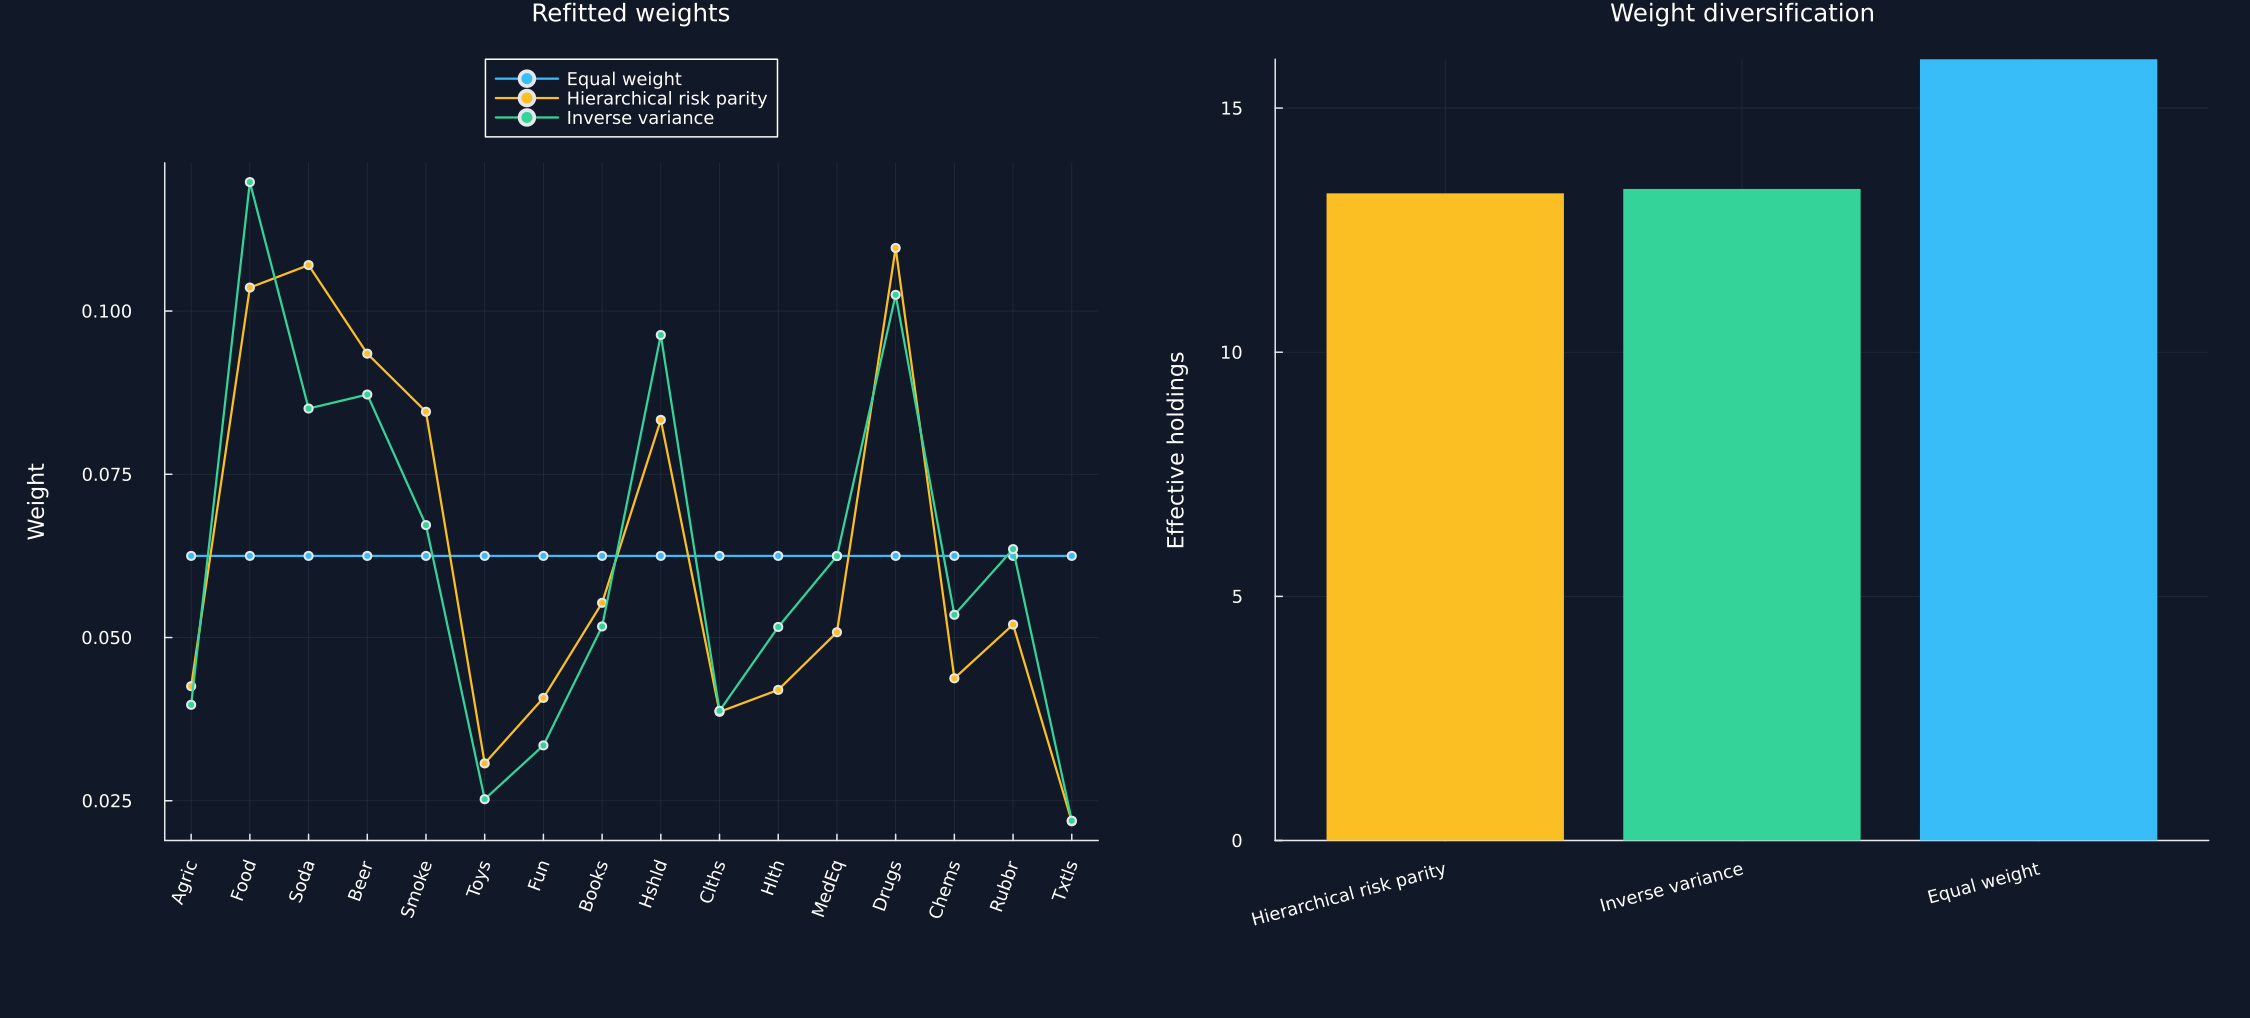

In [4]:
pretest_covariance,pretest_correlation = cov(pretest_returns)*252,cor(pretest_returns)
refitted_weights = Dict(method=>portfolio_weights(method,pretest_covariance,pretest_correlation) for method in methods)
refitted_weight_table = DataFrame("Industry"=>asset_names)
for method in methods
    refitted_weight_table[!,method] = refitted_weights[method]
end
final_table = portfolio_frame([portfolio_record(method,refitted_weights[method],final_returns) for method in methods])
final_best_method = first(final_table.Method)
selected_final_row = only(eachrow(final_table[final_table.Method.==selected_method,:]))
table(refitted_weight_table,"refitted_candidate_weights","Candidate weights refitted with all observations through 2023.")
table(final_table,"final_period_comparison","Final period results for the frozen candidate set.")
p1 = plot(;xticks=(1:16,asset_names),xrotation=70,ylabel="Weight",title="Refitted weights",legend=:outertop,bottom_margin=20Plots.mm)
for method in methods
    plot!(p1,1:16,refitted_weights[method];color=method_colors[method],marker=:circle,markersize=3,linewidth=1.5,label=method)
end
p2 = bar(1:3,final_table[!,"Effective holdings"];color=[method_colors[method] for method in final_table.Method],linealpha=0,legend=false,xticks=(1:3,final_table.Method),xrotation=15,ylabel="Effective holdings",title="Weight diversification",bottom_margin=20Plots.mm)
save_figure(plot(p1,p2;layout=(1,2),size=(1500,680)),paths,"refitted_weights_and_concentration")
save_data(DataFrame(pretest_covariance,:auto),paths,"pretest_covariance")
save_data(DataFrame(pretest_correlation,:auto),paths,"pretest_correlation")
nothing


## Comparing final equity paths

A cumulative path and its drawdown are calculated from daily returns as:

$$
V_t=\prod_{s=1}^{t}(1+r_s),
\qquad D_t=\frac{V_t}{\max_{1\leq u\leq t}V_u}-1.
$$

Here, $r_s$ is a portfolio return on final period day $s$, $V_t$ is cumulative wealth from one unit of initial wealth, and $D_t$ is the percentage distance below the highest wealth observed through day $t$.

Row,Method,Ending wealth,Worst drawdown,Days below prior peak
,String,Float64,Float64,Int64
1,Equal weight,1.15714,-0.149905,459
2,Hierarchical risk parity,1.15737,-0.11703,459
3,Inverse variance,1.13238,-0.126689,465


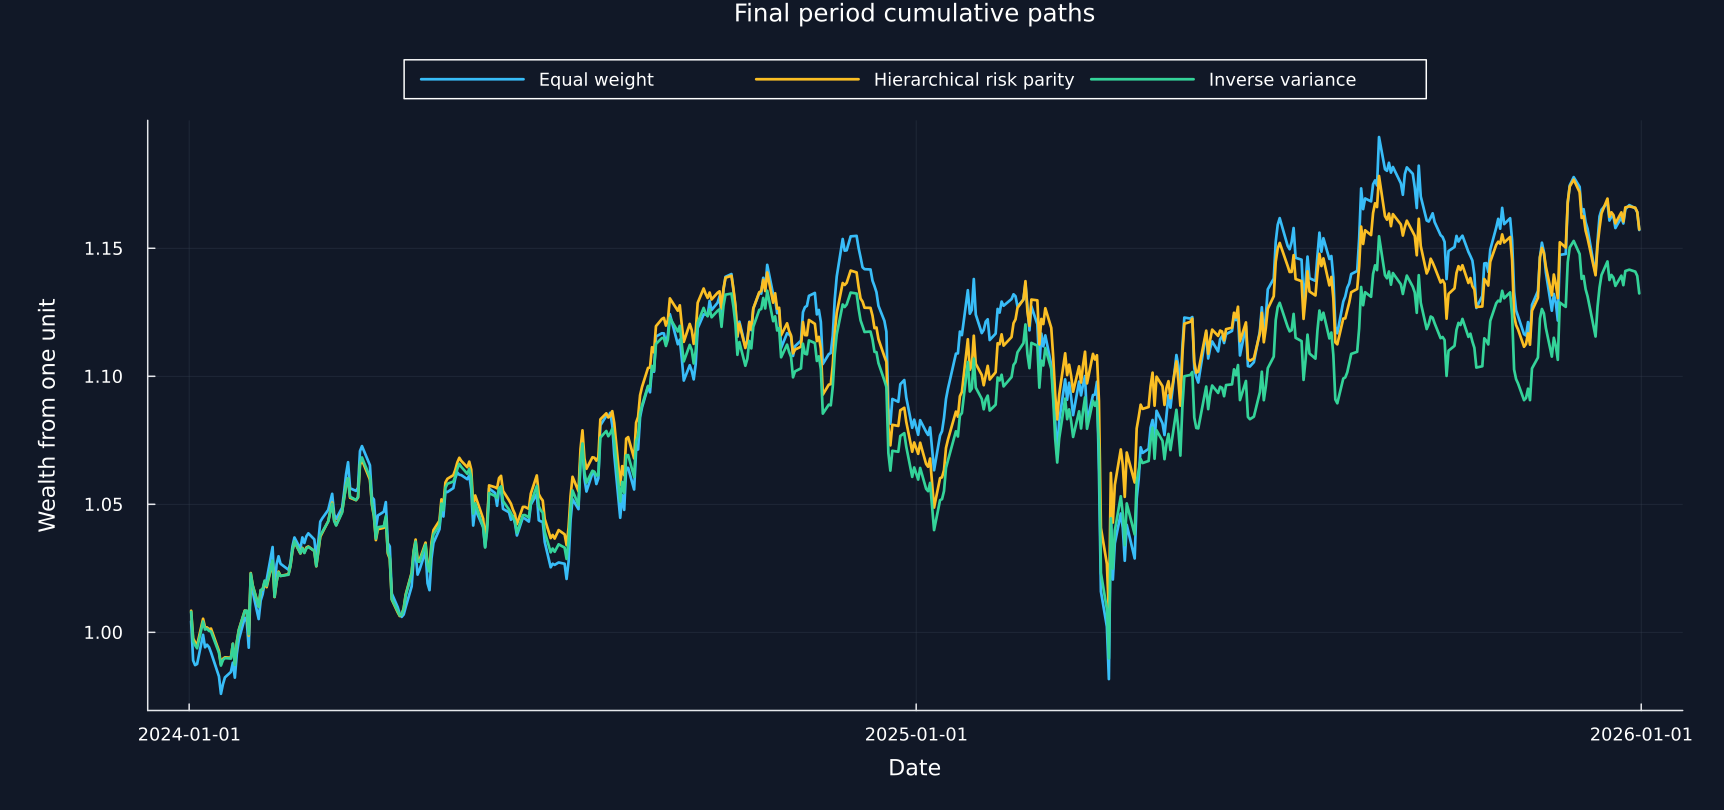

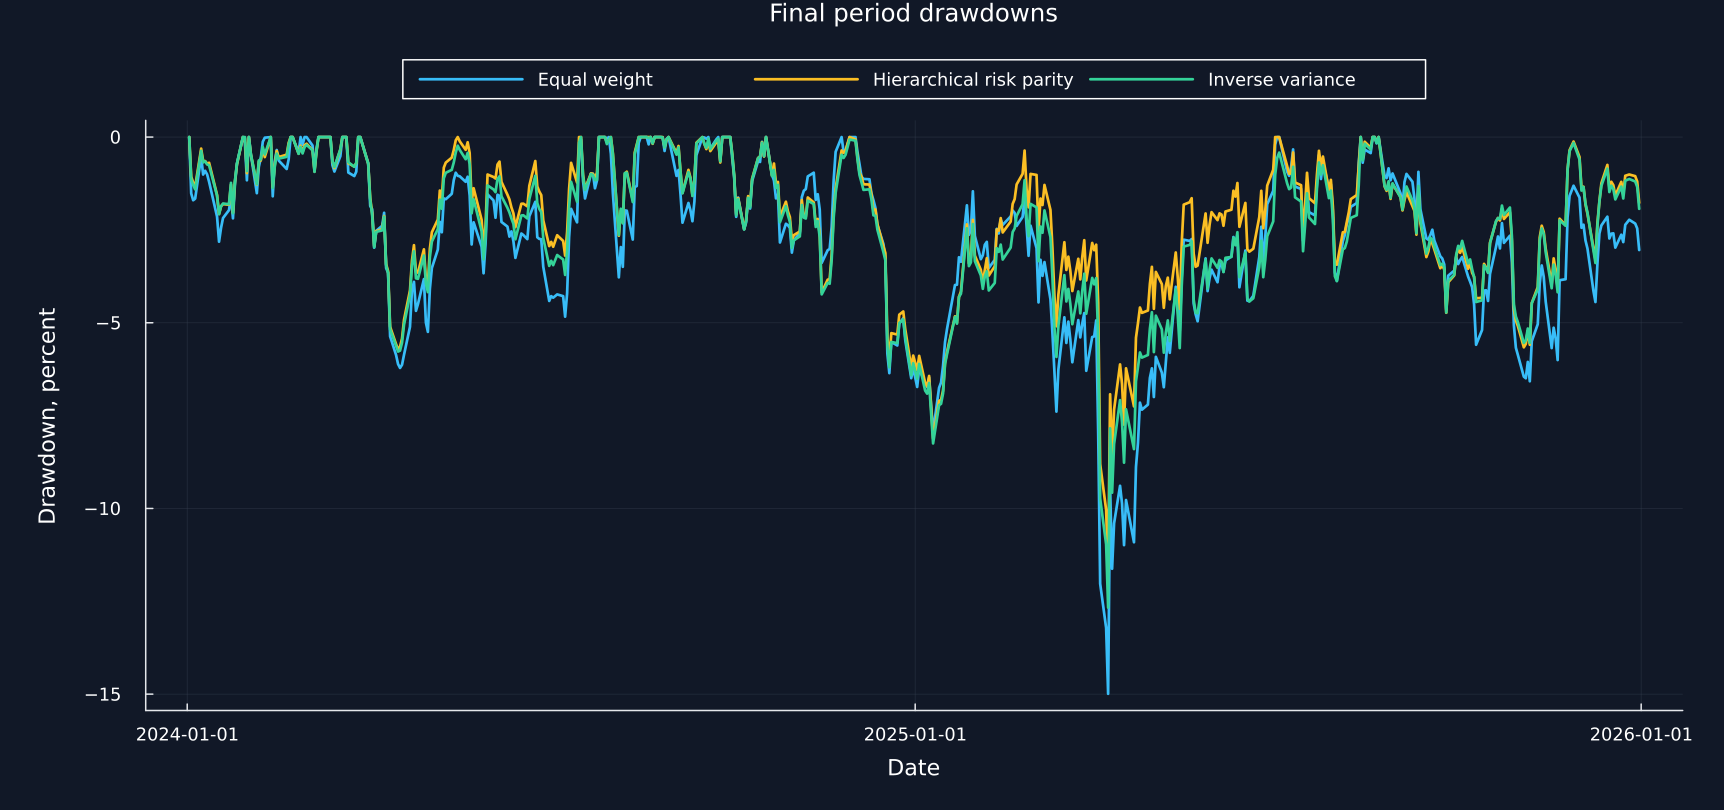

In [5]:
final_dates = dates[final_mask]
final_paths,final_drawdowns = DataFrame("Date"=>final_dates),DataFrame("Date"=>final_dates)
for method in methods
    daily = final_returns*refitted_weights[method]
    wealth = cumprod(1 .+daily)
    final_paths[!,method] = wealth
    final_drawdowns[!,method] = wealth./accumulate(max,wealth).-1
end
final_path_summary = DataFrame("Method"=>methods,"Ending wealth"=>[last(final_paths[!,method]) for method in methods],"Worst drawdown"=>[minimum(final_drawdowns[!,method]) for method in methods],"Days below prior peak"=>[count(<(0),final_drawdowns[!,method]) for method in methods])
table(final_path_summary,"final_path_summary","Cumulative wealth and drawdown summaries in the final period.")
for (frame,scale,name,label,title) in [(final_paths,1.0,"final_cumulative_paths","Wealth from one unit","Final period cumulative paths"),(final_drawdowns,100.0,"final_drawdowns","Drawdown, percent","Final period drawdowns")]
    figure = plot(;xlabel="Date",ylabel=label,title,legend=:outertop,legend_columns=3,size=(1150,540))
    for method in methods
        plot!(figure,final_dates,frame[!,method]*scale;color=method_colors[method],label=method,linewidth=1.8)
    end
    save_figure(figure,paths,name)
    save_data(frame,paths,name)
end
nothing


## Applying the frozen choice to the final period

Row,Question,Answer
,String,Any
1,Method chosen on validation data,Inverse variance
2,Lowest final period volatility,Hierarchical risk parity
3,Chosen method final volatility,0.121613
4,Lowest final volatility,0.120147
5,Chosen method changed after final test,No


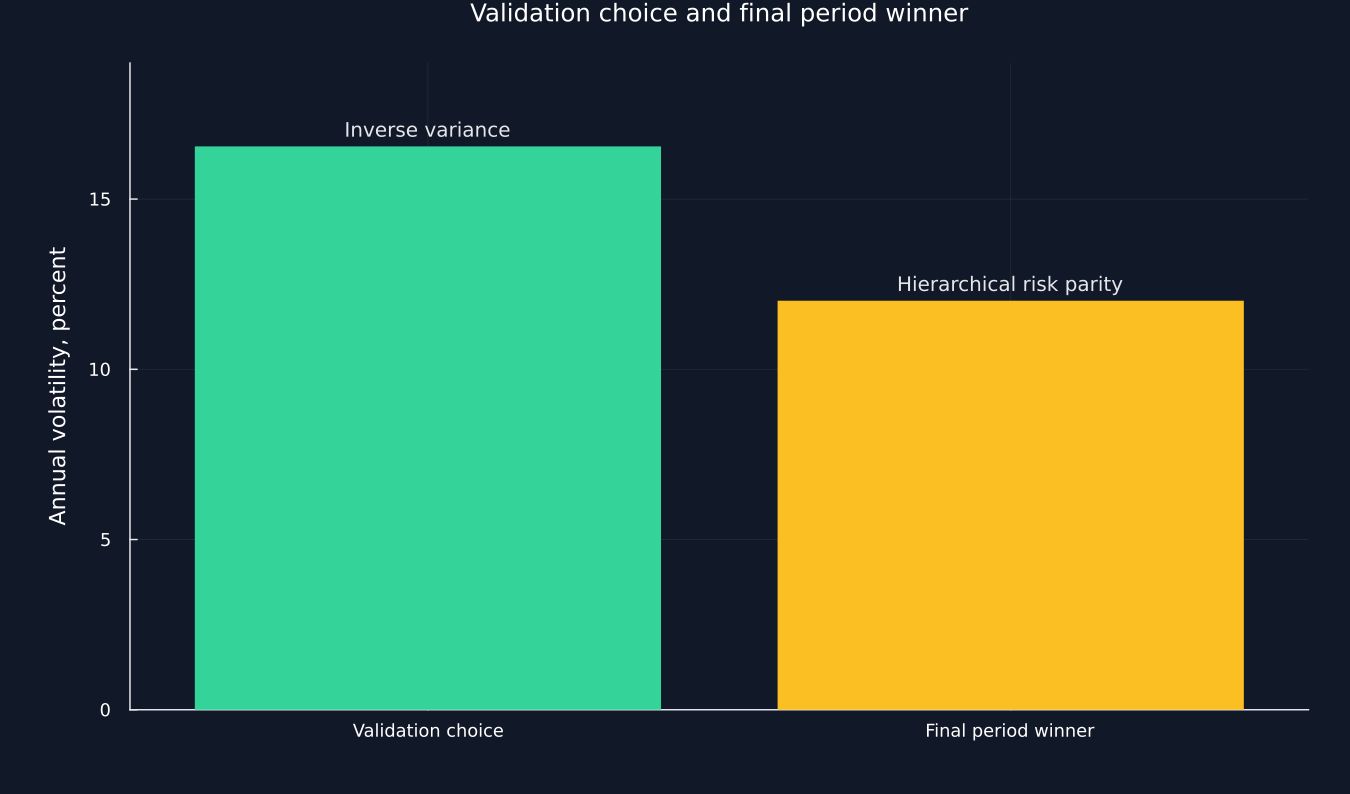

In [6]:
validation_selected_volatility = only(validation_table[validation_table.Method.==selected_method,"Annual volatility"])
final_best_volatility = first(final_table[!,"Annual volatility"])
decision_comparison = DataFrame("Question"=>["Method chosen on validation data","Lowest final period volatility","Chosen method final volatility","Lowest final volatility","Chosen method changed after final test"],"Answer"=>Any[selected_method,final_best_method,selected_final_row["Annual volatility"],final_best_volatility,"No"])
table(decision_comparison,"frozen_decision_comparison","The validation choice is preserved after the final period is observed.")
comparison = DataFrame("Period"=>["Validation choice","Final period winner"],"Annual volatility"=>[validation_selected_volatility,final_best_volatility],"Method"=>[selected_method,final_best_method])
figure = bar(1:2,comparison[!,"Annual volatility"]*100;color=[method_colors[method] for method in comparison.Method],linealpha=0,legend=false,xticks=(1:2,comparison.Period),ylabel="Annual volatility, percent",title="Validation choice and final period winner",ylims=(0,19),size=(900,530))
for (index,row) in enumerate(eachrow(comparison))
    annotate!(figure,index,row["Annual volatility"]*100+.5,text(row.Method,9,palette.text))
end
save_figure(figure,paths,"selected_and_final_best")
save_data(comparison,paths,"selected_and_final_best")
nothing


## Tests

In [7]:
@assert size(public_sample,1)==1760
@assert size.([training_returns,validation_returns,final_returns],1)==[757,501,502]
@assert length(asset_names)==16
@assert methods==sort(methods)
@assert all(isapprox(sum(weights),1.0) for weights in values(training_weights))
@assert all(all(>=(0),weights) for weights in values(training_weights))
@assert all(isapprox(sum(weights),1.0) for weights in values(refitted_weights))
@assert all(all(>=(0),weights) for weights in values(refitted_weights))
@assert selected_method=="Inverse variance"
@assert final_best_method=="Hierarchical risk parity"
@assert isapprox(validation_selected_volatility,.165470;atol=5e-7)
@assert isapprox(selected_final_row["Annual volatility"],.121613;atol=5e-7)
@assert isapprox(final_best_volatility,.120147;atol=5e-7)
@assert last(decision_comparison.Answer)=="No"
@assert all(isfinite,Matrix(final_paths[:,2:end])) && all(isfinite,Matrix(final_drawdowns[:,2:end]))
@assert last(dates[training_mask])<first(dates[validation_mask])
@assert last(dates[validation_mask])<first(final_dates)
@assert count(pretest_mask)==757+501
display(DataFrame("Test"=>["Complete observations","Fixed split","Sixteen industries","Alphabetical method order","Training weight sums","Training long only","Refitted weight sums","Refitted long only","Validation choice","Final period winner","Validation volatility","Chosen final volatility","Lowest final volatility","Frozen choice","Finite paths"],"Passed"=>fill(true,15)))


Row,Test,Passed
,String,Bool
1,Complete observations,true
2,Fixed split,true
3,Sixteen industries,true
4,Alphabetical method order,true
5,Training weight sums,true
6,Training long only,true
7,Refitted weight sums,true
8,Refitted long only,true
9,Validation choice,true
